# Lab 7: Predicting First-Stage Landing with Machine Learning

In [1]:
import os, json, warnings
warnings.filterwarnings('ignore')
os.makedirs('figs', exist_ok=True)
os.makedirs('results', exist_ok=True)

def save_result(name, value):
    path = 'results/results.json'
    data = json.load(open(path)) if os.path.exists(path) else {}
    data[name] = value
    json.dump(data, open(path, 'w'), indent=2, default=str)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
%matplotlib inline

def plot_confusion_matrix(y, y_predict, title, fname):
    from sklearn.metrics import confusion_matrix
    cm = confusion_matrix(y, y_predict)
    plt.figure(figsize=(4.5, 3.8))
    ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    ax.set_xlabel('Predicted labels'); ax.set_ylabel('True labels'); ax.set_title(title)
    ax.xaxis.set_ticklabels(['did not land', 'landed']); ax.yaxis.set_ticklabels(['did not land', 'landed'])
    plt.savefig(fname, dpi=120, bbox_inches='tight')
    plt.show()
    return cm.tolist()

In [2]:
data = pd.read_csv('dataset_part_2.csv')
X = pd.read_csv('dataset_part_3.csv')

### Task 1: Create the label array Y

In [3]:
Y = data['Class'].to_numpy()
Y[:10]

array([0, 0, 0, 0, 0, 0, 1, 1, 0, 0])

### Task 2: Standardize the features

In [4]:
transform = preprocessing.StandardScaler()
X = transform.fit_transform(X)

### Task 3: Split into training and test data

In [5]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
save_result('test_samples', int(Y_test.shape[0]))
print('Train:', X_train.shape[0], ' Test:', Y_test.shape[0])

Train: 72  Test: 18


### Tasks 4-11: Tune four classifiers with GridSearchCV (cv=10) and evaluate on the test set

In [6]:
models = {
    'Logistic Regression': (LogisticRegression(), {'C': [0.01, 0.1, 1], 'penalty': ['l2'], 'solver': ['lbfgs']}),
    'SVM': (SVC(), {'kernel': ('linear', 'rbf', 'poly', 'sigmoid'), 'C': np.logspace(-3, 3, 5), 'gamma': np.logspace(-3, 3, 5)}),
    'Decision Tree': (DecisionTreeClassifier(random_state=42), {'criterion': ['gini', 'entropy'], 'splitter': ['best', 'random'],
                       'max_depth': [2 * n for n in range(1, 10)], 'max_features': ['sqrt'],
                       'min_samples_leaf': [1, 2, 4], 'min_samples_split': [2, 5, 10]}),
    'KNN': (KNeighborsClassifier(), {'n_neighbors': list(range(1, 11)), 'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'], 'p': [1, 2]}),
}
results, fitted = {}, {}
for name, (est, params) in models.items():
    cv = GridSearchCV(est, params, cv=10)
    cv.fit(X_train, Y_train)
    fitted[name] = cv
    results[name] = {'best_params': {k: (v.item() if hasattr(v, 'item') else v) for k, v in cv.best_params_.items()},
                     'cv_accuracy': round(float(cv.best_score_), 4),
                     'test_accuracy': round(float(cv.score(X_test, Y_test)), 4)}
    print(f"{name:20s} CV accuracy {cv.best_score_:.4f}  test accuracy {cv.score(X_test, Y_test):.4f}  {cv.best_params_}")

Logistic Regression  CV accuracy 0.8214  test accuracy 0.8333  {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}


SVM                  CV accuracy 0.8482  test accuracy 0.8333  {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}


Decision Tree        CV accuracy 0.8196  test accuracy 0.6667  {'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'splitter': 'random'}


KNN                  CV accuracy 0.8339  test accuracy 0.8333  {'algorithm': 'auto', 'n_neighbors': 6, 'p': 1}


### Confusion matrices

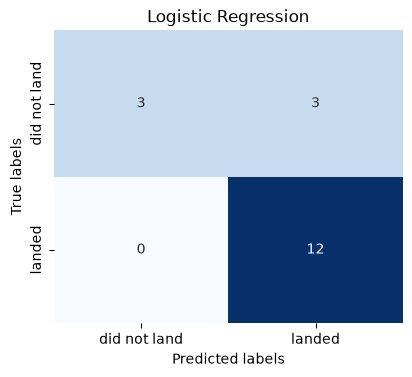

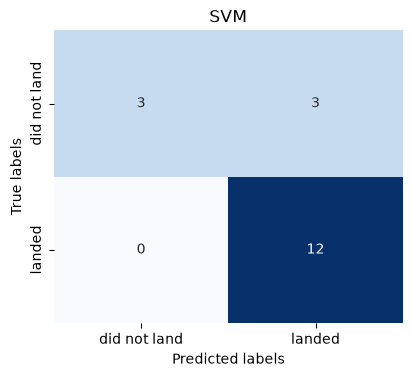

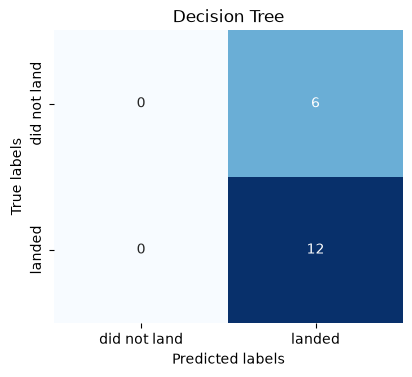

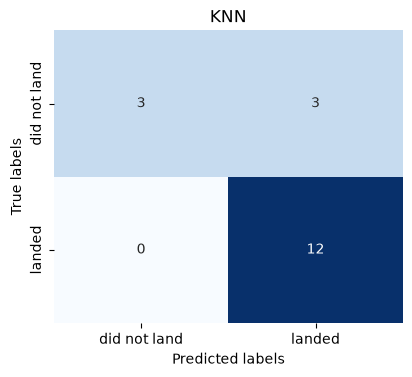

In [7]:
cms = {}
for name, cv in fitted.items():
    fname = 'figs/cm_' + name.lower().replace(' ', '_') + '.png'
    cms[name] = plot_confusion_matrix(Y_test, cv.predict(X_test), name, fname)
for name in results:
    results[name]['confusion_matrix'] = cms[name]
save_result('ml_results', results)

### Task 12: Which model performs best?

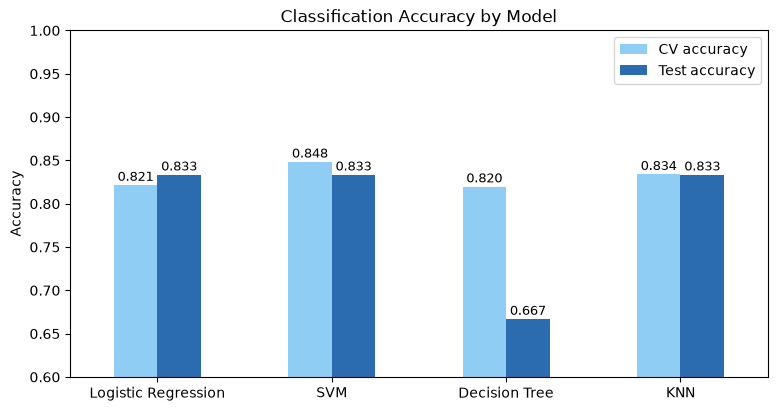

Best model (highest cross-validation accuracy): SVM


,CV accuracy,Test accuracy
Logistic Regression,0.8214,0.8333
SVM,0.8482,0.8333
Decision Tree,0.8196,0.6667
KNN,0.8339,0.8333


In [8]:
summary = pd.DataFrame({n: {'CV accuracy': r['cv_accuracy'], 'Test accuracy': r['test_accuracy']} for n, r in results.items()}).T
best = summary.sort_values(['CV accuracy', 'Test accuracy'], ascending=False).index[0]
save_result('best_model', best)

ax = summary.plot(kind='bar', figsize=(9, 4.5), color=['#90cdf4', '#2b6cb0'], rot=0)
ax.set_ylim(0.6, 1.0); ax.set_ylabel('Accuracy'); ax.set_title('Classification Accuracy by Model')
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2, p.get_height() + 0.005), ha='center', fontsize=9)
plt.savefig('figs/model_accuracy.png', dpi=120, bbox_inches='tight')
plt.show()
print('Best model (highest cross-validation accuracy):', best)
summary

### Extra insight: what drives the decision tree's predictions?

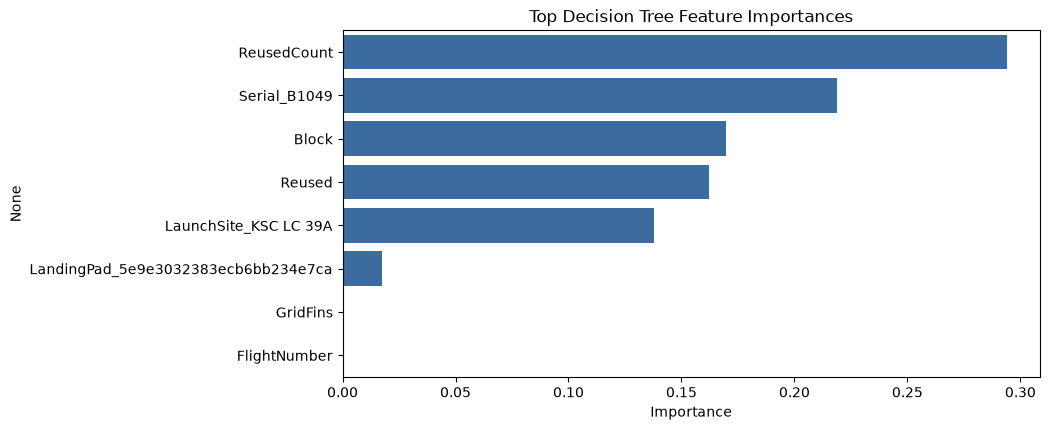

In [9]:
cols = pd.read_csv('dataset_part_3.csv').columns
tree = fitted['Decision Tree'].best_estimator_
imp = pd.Series(tree.feature_importances_, index=cols).sort_values(ascending=False).head(8)
save_result('tree_importances', imp.round(3).to_dict())
plt.figure(figsize=(9, 4.5))
sns.barplot(x=imp.values, y=imp.index, color='#2b6cb0')
plt.xlabel('Importance'); plt.title('Top Decision Tree Feature Importances')
plt.savefig('figs/tree_importance.png', dpi=120, bbox_inches='tight')
plt.show()